# Mental Health & Social Media Balance
### Data Analysis | Exploratory Analysis & Insights

**Project focus:** Exploring associations between digital habits, lifestyle factors, and self-reported well-being.

> This analysis is observational. Correlation and group comparisons describe patterns in this sample and do not establish cause-and-effect relationships.

---

## 01 · Project Overview

### Business / Research Question
How are social media usage patterns and lifestyle habits associated with users' reported sleep quality, stress, and happiness?

### Objectives
- Understand the sample's demographic and platform profile.
- Explore screen time in relation to sleep, stress, and happiness.
- Investigate whether social-media breaks and exercise show noticeable patterns.
- Compare well-being measures across platforms and demographic groups.
- Translate findings into careful, practical recommendations.

### Analytical Approach
**Data profiling → Quality validation → Feature preparation → KPI overview → Exploratory visuals → Correlation analysis → Insights & recommendations**

In [3]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

COLORS = {
    "navy": "#14213D",
    "blue": "#3867D6",
    "teal": "#20A39E",
    "purple": "#8B5CF6",
    "coral": "#E76F51",
    "gold": "#F4B942",
    "green": "#2E8B57",
    "red": "#C94C4C",
    "gray": "#667085",
    "light": "#E8EEF5",
    "dark": "#263238"
}


THEMES = {
    "dark": {"bg": "#101827", "axes": "#172235", "text": "#EAF0F8", "grid": "#34445C", "spine": "#44536C"},
    "slate": {"bg": "#202631", "axes": "#29323F", "text": "#F1F5F9", "grid": "#414C5C", "spine": "#566477"},
    "pastel": {"bg": "#FBF8FF", "axes": "#FFFFFF", "text": "#3E3B56", "grid": "#E9E2F2", "spine": "#D9D1E5"},
    "clean": {"bg": "#FFFFFF", "axes": "#FFFFFF", "text": "#263238", "grid": "#E7ECF2", "spine": "#D9E1EA"}
}

def set_theme(name="clean"):
    theme = THEMES[name]
    plt.rcParams.update({
        "axes.facecolor": theme["axes"], "figure.facecolor": theme["bg"],
        "axes.edgecolor": theme["spine"], "axes.labelcolor": theme["text"],
        "axes.titlecolor": theme["text"], "xtick.color": theme["text"],
        "ytick.color": theme["text"], "grid.color": theme["grid"],
        "text.color": theme["text"], "legend.labelcolor": theme["text"],
        "legend.facecolor": theme["axes"], "legend.edgecolor": theme["spine"]
    })

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.facecolor": "#FFFFFF",
    "figure.facecolor": "#FFFFFF",
    "axes.edgecolor": "#D9E1EA",
    "axes.labelcolor": COLORS["dark"],
    "axes.titlecolor": COLORS["navy"],
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "font.size": 10,
    "xtick.color": COLORS["gray"],
    "ytick.color": COLORS["gray"],
    "grid.color": "#E7ECF2",
    "grid.alpha": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def style_ax(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, linestyle="--", linewidth=0.7, alpha=0.7)
    ax.set_axisbelow(True)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_color("#D9E1EA")

def label_bars(ax, fmt="{:.1f}", padding=3):
    for bar in ax.patches:
        value = bar.get_width()
        ax.annotate(fmt.format(value),
                    (bar.get_x() + bar.get_width()/2, value),
                    xytext=(0, padding), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color=COLORS["dark"])

def format_percent(value):
    return f"{value:.1f}%"

## 02 · Load Dataset

Update the CSV path below if your file name or location is different.

In [4]:
# Load the dataset
DATA_PATH = "/content/Mental_Health_and_Social_Media_Balance_Dataset.csv"

df = pd.read_csv(DATA_PATH)
print(df.head().to_string())

  User_ID  Age  Gender  Daily_Screen_Time(hrs)  Sleep_Quality(1-10)  Stress_Level(1-10)  Days_Without_Social_Media  Exercise_Frequency(week) Social_Media_Platform  Happiness_Index(1-10)
0    U001   44    Male                    3.10                 7.00                6.00                       2.00                      5.00              Facebook                  10.00
1    U002   30   Other                    5.10                 7.00                8.00                       5.00                      3.00              LinkedIn                  10.00
2    U003   23   Other                    7.40                 6.00                7.00                       1.00                      3.00               YouTube                   6.00
3    U004   36  Female                    5.70                 7.00                8.00                       1.00                      1.00                TikTok                   8.00
4    U005   34  Female                    7.00                 4.00   

## 03 · Dataset Structure

In [5]:
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\\nColumn names:")
print(df.columns.tolist())

df.info()
print(df.describe(include="all").T.to_string())

Dataset shape: 500 rows × 10 columns
\nColumn names:
['User_ID', 'Age', 'Gender', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)', 'Social_Media_Platform', 'Happiness_Index(1-10)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   User_ID                    500 non-null    object 
 1   Age                        500 non-null    int64  
 2   Gender                     500 non-null    object 
 3   Daily_Screen_Time(hrs)     500 non-null    float64
 4   Sleep_Quality(1-10)        500 non-null    float64
 5   Stress_Level(1-10)         500 non-null    float64
 6   Days_Without_Social_Media  500 non-null    float64
 7   Exercise_Frequency(week)   500 non-null    float64
 8   Social_Media_Platform      500 non-null    object 
 9   Happiness_Inde

## 04 · Data Quality Audit

Check missing values, duplicates, ID uniqueness, data types, and value ranges before analysis.

In [6]:
quality_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})
print(quality_summary.to_string())

print("Duplicate rows:", df.duplicated().sum())
if "User_ID" in df.columns:
    print("Duplicate User_ID values:", df["User_ID"].duplicated().sum())

                           Missing Values  Missing (%)  Unique Values Data Type
User_ID                                 0         0.00            500    object
Age                                     0         0.00             34     int64
Gender                                  0         0.00              3    object
Daily_Screen_Time(hrs)                  0         0.00             82   float64
Sleep_Quality(1-10)                     0         0.00              9   float64
Stress_Level(1-10)                      0         0.00              9   float64
Days_Without_Social_Media               0         0.00              9   float64
Exercise_Frequency(week)                0         0.00              8   float64
Social_Media_Platform                   0         0.00              6    object
Happiness_Index(1-10)                   0         0.00              7   float64
Duplicate rows: 0
Duplicate User_ID values: 0


### Range Validation

In [7]:
# Expected value ranges based on the dataset's scale
range_checks = {
    "Age": (0, 120),
    "Daily_Screen_Time(hrs)": (0, 24),
    "Sleep_Quality(1-10)": (1, 10),
    "Stress_Level(1-10)": (1, 10),
    "Days_Without_Social_Media": (0, 365),
    "Exercise_Frequency(week)": (0, 7),
    "Happiness_Index(1-10)": (1, 10)
}

range_report = []
for column, (low, high) in range_checks.items():
    if column in df.columns:
        invalid = df[column].notna() & ~df[column].between(low, high)
        range_report.append({
            "Column": column,
            "Expected Min": low,
            "Expected Max": high,
            "Invalid Values": int(invalid.sum())
        })

print(pd.DataFrame(range_report).to_string(index=False))

                   Column  Expected Min  Expected Max  Invalid Values
                      Age             0           120               0
   Daily_Screen_Time(hrs)             0            24               0
      Sleep_Quality(1-10)             1            10               0
       Stress_Level(1-10)             1            10               0
Days_Without_Social_Media             0           365               0
 Exercise_Frequency(week)             0             7               0
    Happiness_Index(1-10)             1            10               0


## 05 · Data Preparation

Standardize column labels for analysis, preserve the original dataset, and create convenient derived fields.

In [8]:
data = df.copy()

# Trim whitespace in text fields
text_columns = data.select_dtypes(include="object").columns
for column in text_columns:
    data[column] = data[column].astype("string").str.strip()

# Convert expected numeric columns safely
numeric_columns = [
    "Age", "Daily_Screen_Time(hrs)", "Sleep_Quality(1-10)",
    "Stress_Level(1-10)", "Days_Without_Social_Media",
    "Exercise_Frequency(week)", "Happiness_Index(1-10)"
]
for column in numeric_columns:
    if column in data.columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")

# Create clearer analysis labels
rename_map = {
    "Daily_Screen_Time(hrs)": "Screen_Time_Hours",
    "Sleep_Quality(1-10)": "Sleep_Quality",
    "Stress_Level(1-10)": "Stress_Level",
    "Days_Without_Social_Media": "Social_Media_Break_Days",
    "Exercise_Frequency(week)": "Exercise_Days_Per_Week",
    "Happiness_Index(1-10)": "Happiness"
}
data = data.rename(columns=rename_map)

# Age groups
data["Age_Group"] = pd.cut(
    data["Age"],
    bins=[0, 19, 24, 29, 34, 39, 44, 49, 120],
    labels=["≤19", "20–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50+"],
    include_lowest=True
)

# Screen-time groups
screen_bins = [0, 3, 4, 5, 6, 7, 8, 24]
screen_labels = ["≤3", "3–4", "4–5", "5–6", "6–7", "7–8", ">8"]
data["Screen_Time_Band"] = pd.cut(
    data["Screen_Time_Hours"],
    bins=screen_bins,
    labels=screen_labels,
    right=True,
    include_lowest=True
)

print(data.head().to_string())

  User_ID  Age  Gender  Screen_Time_Hours  Sleep_Quality  Stress_Level  Social_Media_Break_Days  Exercise_Days_Per_Week Social_Media_Platform  Happiness Age_Group Screen_Time_Band
0    U001   44    Male               3.10           7.00          6.00                     2.00                    5.00              Facebook      10.00     40–44              3–4
1    U002   30   Other               5.10           7.00          8.00                     5.00                    3.00              LinkedIn      10.00     30–34              5–6
2    U003   23   Other               7.40           6.00          7.00                     1.00                    3.00               YouTube       6.00     20–24              7–8
3    U004   36  Female               5.70           7.00          8.00                     1.00                    1.00                TikTok       8.00     35–39              5–6
4    U005   34  Female               7.00           4.00          7.00                     5.00     

## 06 · KPI Snapshot

The following indicators summarize the dataset. Values are calculated from the loaded data.

In [9]:
n_users = len(data)
kpis = {
    "Users / Records": n_users,
    "Average Screen Time (hrs)": data["Screen_Time_Hours"].mean(),
    "Average Sleep Quality": data["Sleep_Quality"].mean(),
    "Average Stress": data["Stress_Level"].mean(),
    "Average Happiness": data["Happiness"].mean(),
    "Average Exercise Days / Week": data["Exercise_Days_Per_Week"].mean(),
    "Average Break Days": data["Social_Media_Break_Days"].mean(),
    "Unique Platforms": data["Social_Media_Platform"].nunique(),
    "Average Age": data["Age"].mean()
}
kpi_df = pd.DataFrame({"Metric": kpis.keys(), "Value": kpis.values()})
print(kpi_df.to_string(index=False))

                      Metric  Value
             Users / Records 500.00
   Average Screen Time (hrs)   5.53
       Average Sleep Quality   6.30
              Average Stress   6.62
           Average Happiness   8.38
Average Exercise Days / Week   2.45
          Average Break Days   3.13
            Unique Platforms   6.00
                 Average Age  32.99


## 07 · Demographic & Platform Profile

### Gender composition

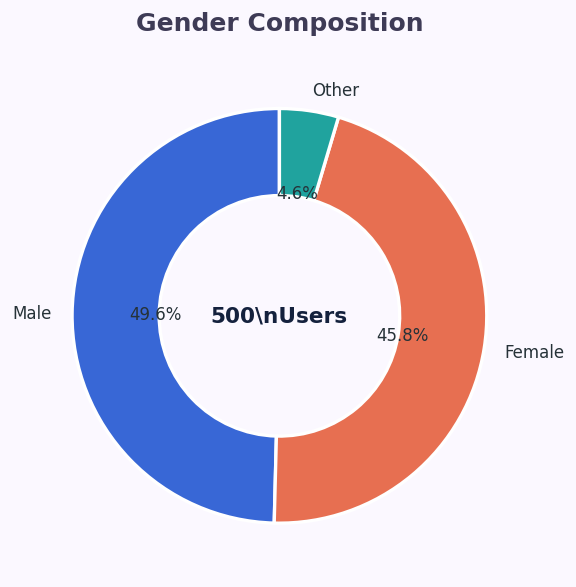

In [10]:
set_theme("pastel")

gender_counts = data["Gender"].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(7, 5))
wedges, texts, autotexts = ax.pie(
    gender_counts.values,
    labels=gender_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    colors=[COLORS["blue"], COLORS["coral"], COLORS["teal"], COLORS["purple"]],
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    textprops={"color": COLORS["dark"], "fontsize": 10}
)
ax.set_title("Gender Composition", pad=16)
ax.text(0, 0, f"{len(data):,}\\nUsers", ha="center", va="center",
        fontsize=13, fontweight="bold", color=COLORS["navy"])
plt.tight_layout()
plt.show()

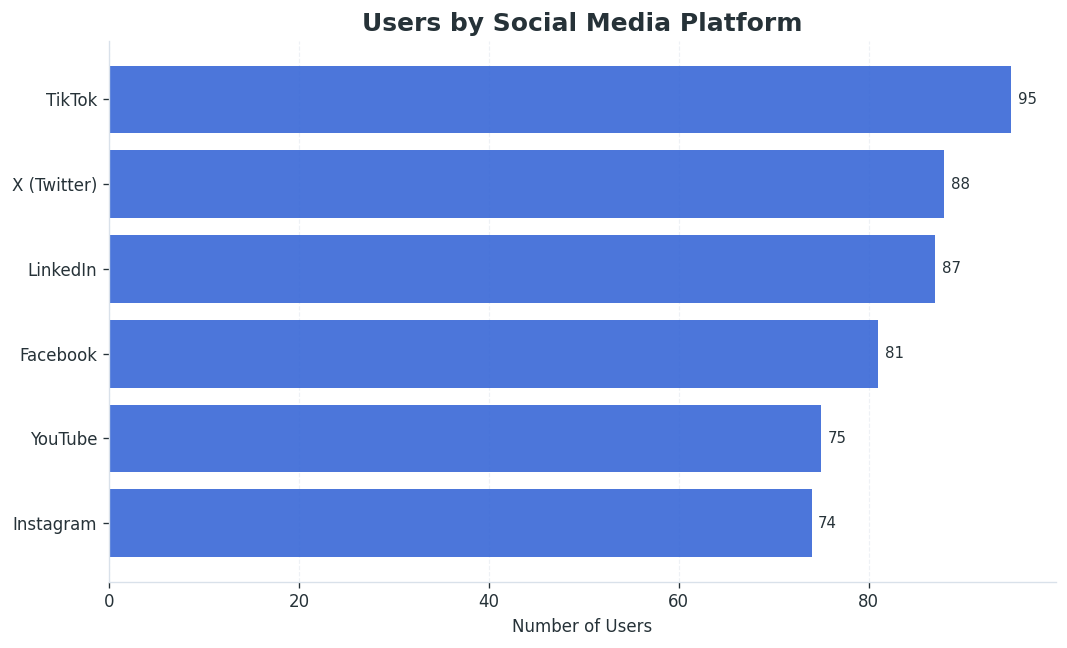

In [11]:
set_theme("clean")

platform_counts = data["Social_Media_Platform"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(platform_counts.index, platform_counts.values,
                color=COLORS["blue"], alpha=0.9)
ax.bar_label(bars, padding=4, fontsize=9)
ax.set_title("Users by Social Media Platform")
ax.set_xlabel("Number of Users")
style_ax(ax, "x")
plt.tight_layout()
plt.show()

### Age distribution

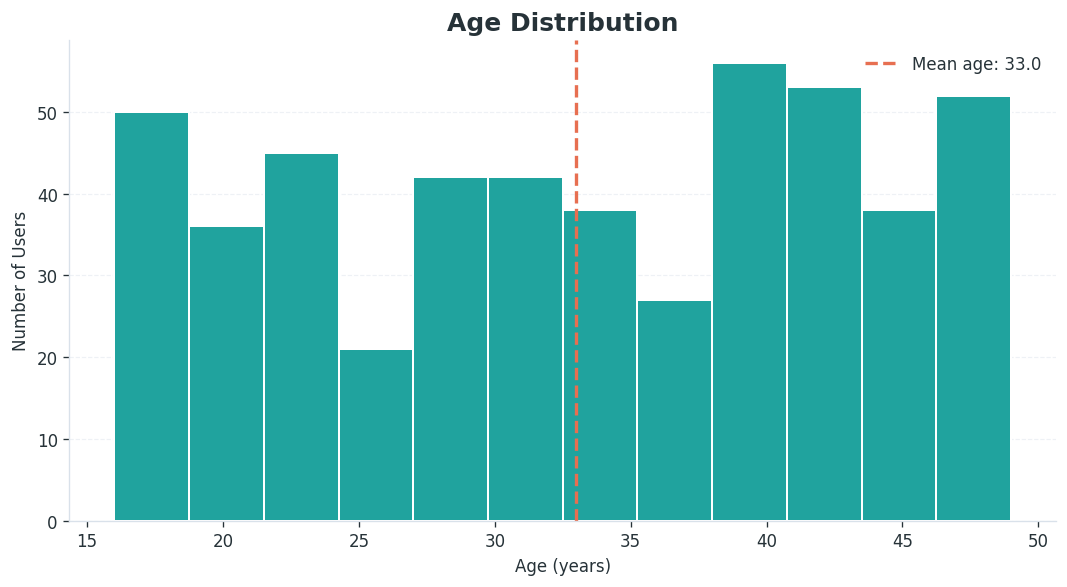

In [12]:
set_theme("clean")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(data["Age"].dropna(), bins=12, color=COLORS["teal"], edgecolor="white", linewidth=1.2)
ax.axvline(data["Age"].mean(), color=COLORS["coral"], linestyle="--", linewidth=2,
           label=f"Mean age: {data['Age'].mean():.1f}")
ax.set_title("Age Distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of Users")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()


## 08 · Screen Time & Well-being

### Daily screen time distribution

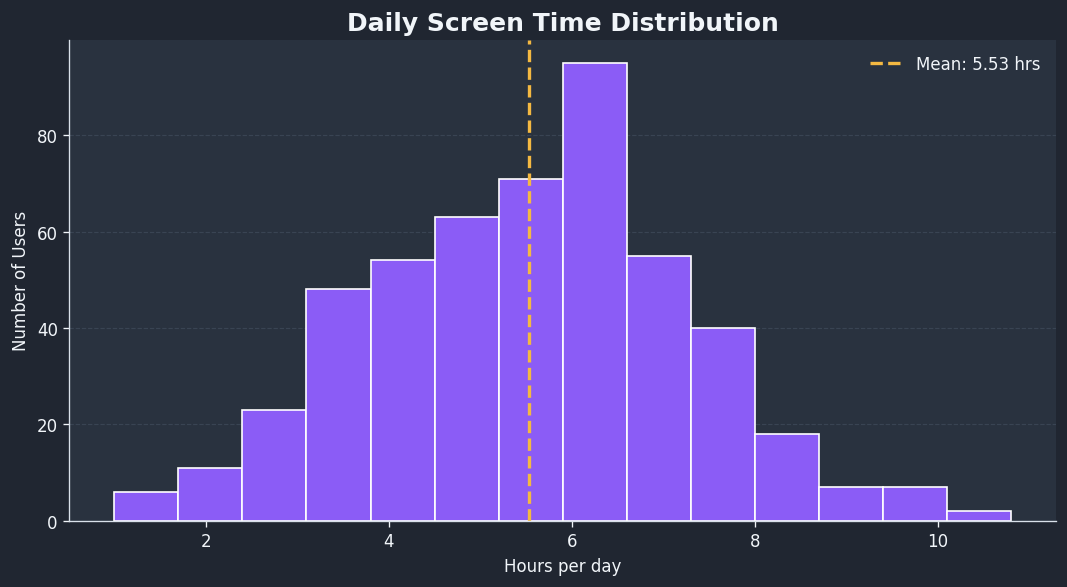

In [13]:
set_theme("slate")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(data["Screen_Time_Hours"].dropna(), bins=14,
        color=COLORS["purple"], edgecolor="white")
ax.axvline(data["Screen_Time_Hours"].mean(), color=COLORS["gold"],
           linewidth=2, linestyle="--",
           label=f"Mean: {data['Screen_Time_Hours'].mean():.2f} hrs")
ax.set_title("Daily Screen Time Distribution")
ax.set_xlabel("Hours per day")
ax.set_ylabel("Number of Users")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()

### Screen time vs. happiness
Each dot represents one user. A trend line is included to visualize the overall direction only.

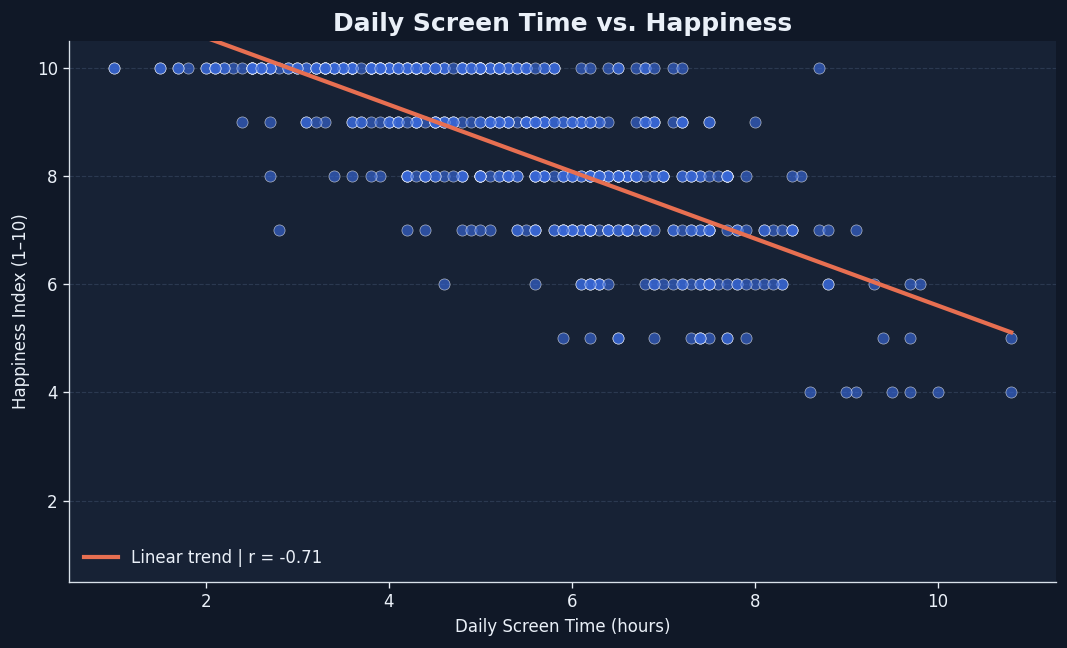

Correlation: -0.705


In [14]:
set_theme("dark")

plot_data = data[["Screen_Time_Hours", "Happiness"]].dropna()
corr_screen_happiness = plot_data["Screen_Time_Hours"].corr(plot_data["Happiness"])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(plot_data["Screen_Time_Hours"], plot_data["Happiness"],
          alpha=0.65, s=45, color=COLORS["blue"], edgecolors="white", linewidth=0.4)

m, b = np.polyfit(plot_data["Screen_Time_Hours"], plot_data["Happiness"], 1)
x_line = np.linspace(plot_data["Screen_Time_Hours"].min(),
                    plot_data["Screen_Time_Hours"].max(), 100)
ax.plot(x_line, m*x_line+b, color=COLORS["coral"], linewidth=2.5,
        label=f"Linear trend | r = {corr_screen_happiness:.2f}")

ax.set_title("Daily Screen Time vs. Happiness")
ax.set_xlabel("Daily Screen Time (hours)")
ax.set_ylabel("Happiness Index (1–10)")
ax.set_ylim(0.5, 10.5)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(f"Correlation: {corr_screen_happiness:.3f}")

### Happiness across screen-time bands

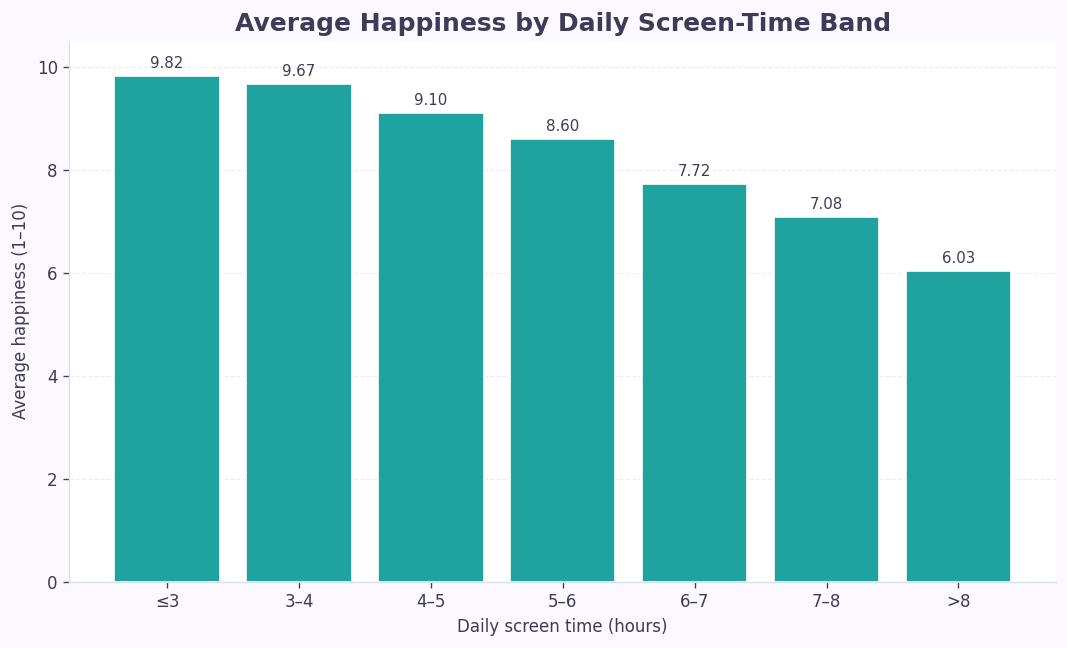

                  Users  Mean_Happiness  Mean_Stress  Mean_Sleep
Screen_Time_Band                                                
≤3                   40            9.82         4.35        8.38
3–4                  63            9.67         5.30        7.71
4–5                  93            9.10         6.09        6.89
5–6                 100            8.60         6.51        6.31
6–7                 109            7.72         7.37        5.67
7–8                  63            7.08         7.94        4.89
>8                   32            6.03         8.78        4.16


In [15]:
set_theme("pastel")

band_summary = data.groupby("Screen_Time_Band", observed=False).agg(
    Users=("Happiness", "size"),
    Mean_Happiness=("Happiness", "mean"),
    Mean_Stress=("Stress_Level", "mean"),
    Mean_Sleep=("Sleep_Quality", "mean")
).dropna(subset=["Mean_Happiness"])

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(band_summary.index.astype(str), band_summary["Mean_Happiness"],
              color=COLORS["teal"], edgecolor="white")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_title("Average Happiness by Daily Screen-Time Band")
ax.set_xlabel("Daily screen time (hours)")
ax.set_ylabel("Average happiness (1–10)")
ax.set_ylim(0, 10.5)
style_ax(ax)
plt.tight_layout()
plt.show()

print(band_summary.round(2).to_string())

## 09 · Sleep, Stress & Happiness

### Sleep quality vs. stress

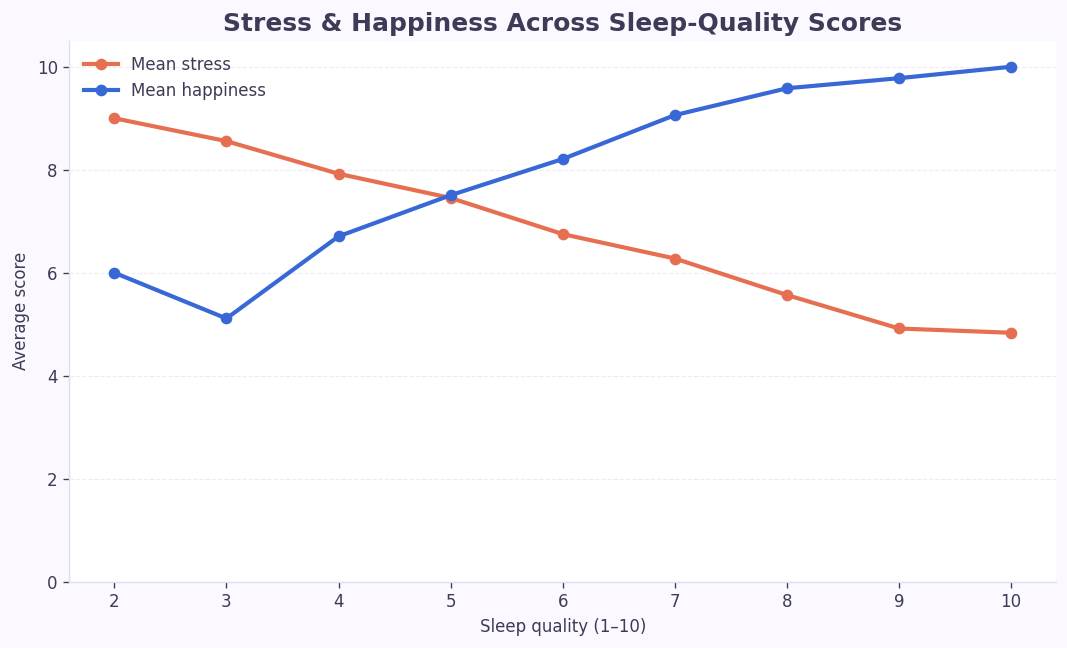

               Users  Mean_Stress  Mean_Happiness
Sleep_Quality                                    
2.00               2         9.00            6.00
3.00               9         8.56            5.11
4.00              51         7.92            6.71
5.00              93         7.45            7.51
6.00             120         6.75            8.21
7.00             116         6.28            9.06
8.00              67         5.57            9.58
9.00              36         4.92            9.78
10.00              6         4.83           10.00


In [16]:
set_theme("pastel")

sleep_summary = data.groupby("Sleep_Quality").agg(
    Users=("Stress_Level", "size"),
    Mean_Stress=("Stress_Level", "mean"),
    Mean_Happiness=("Happiness", "mean")
).sort_index()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(sleep_summary.index, sleep_summary["Mean_Stress"], marker="o",
         linewidth=2.5, color=COLORS["coral"], label="Mean stress")
ax.plot(sleep_summary.index, sleep_summary["Mean_Happiness"], marker="o",
         linewidth=2.5, color=COLORS["blue"], label="Mean happiness")
ax.set_title("Stress & Happiness Across Sleep-Quality Scores")
ax.set_xlabel("Sleep quality (1–10)")
ax.set_ylabel("Average score")
ax.set_ylim(0, 10.5)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(sleep_summary.round(2).to_string())

### Sleep quality vs. happiness

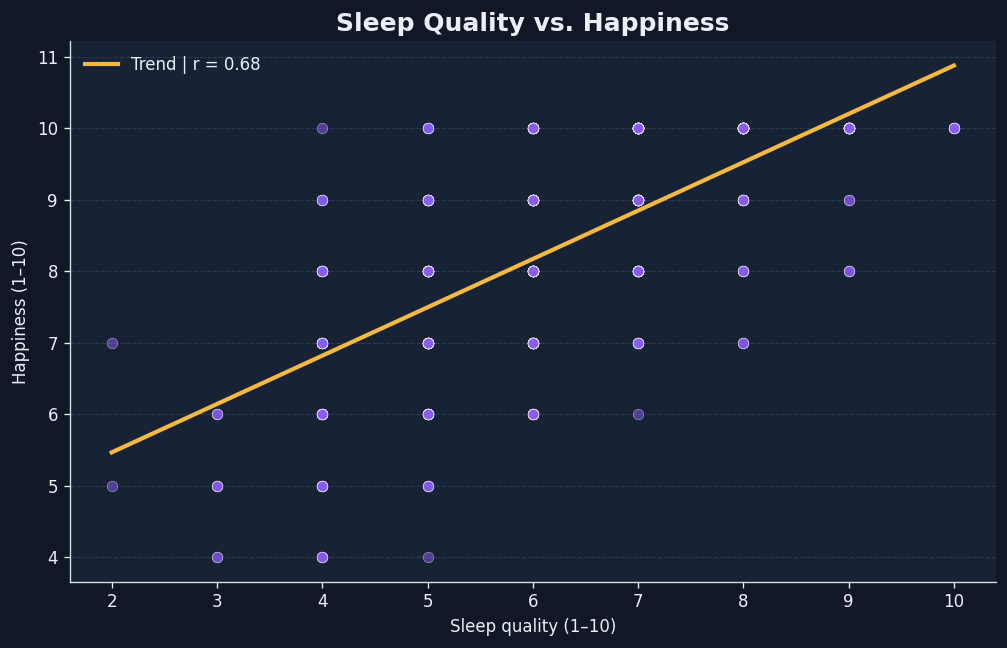

Sleep–happiness correlation: 0.679


In [17]:
set_theme("dark")

sleep_corr_happiness = data[["Sleep_Quality", "Happiness"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(data["Sleep_Quality"], data["Happiness"], alpha=0.5,
          color=COLORS["purple"], s=40, edgecolors="white", linewidth=0.4)
m, b = np.polyfit(data["Sleep_Quality"].dropna(), data["Happiness"].dropna(), 1)
x = np.linspace(data["Sleep_Quality"].min(), data["Sleep_Quality"].max(), 100)
ax.plot(x, m*x+b, color=COLORS["gold"], linewidth=2.5,
        label=f"Trend | r = {sleep_corr_happiness:.2f}")
ax.set_title("Sleep Quality vs. Happiness")
ax.set_xlabel("Sleep quality (1–10)")
ax.set_ylabel("Happiness (1–10)")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(f"Sleep–happiness correlation: {sleep_corr_happiness:.3f}")

## 10 · Social Media Breaks

### Break days vs. happiness and stress

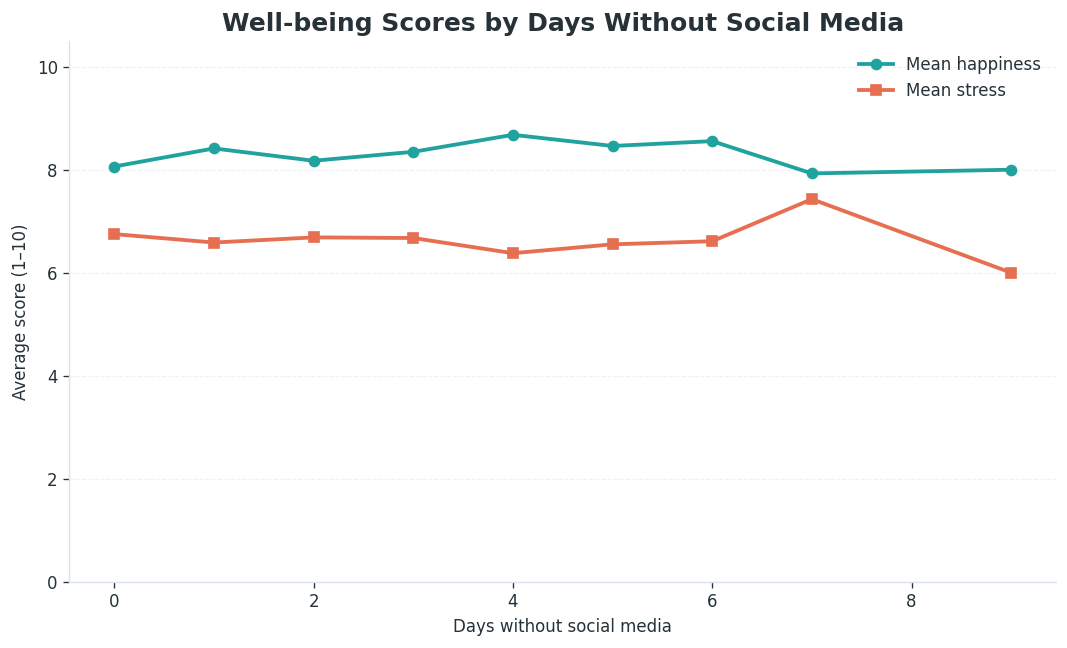

                         Users  Mean_Happiness  Mean_Stress
Social_Media_Break_Days                                    
0.00                        48            8.06         6.75
1.00                        58            8.41         6.59
2.00                        86            8.17         6.69
3.00                        92            8.35         6.67
4.00                        87            8.68         6.38
5.00                        78            8.46         6.55
6.00                        36            8.56         6.61
7.00                        14            7.93         7.43
9.00                         1            8.00         6.00


In [18]:
set_theme("clean")

break_summary = data.groupby("Social_Media_Break_Days").agg(
    Users=("Happiness", "size"),
    Mean_Happiness=("Happiness", "mean"),
    Mean_Stress=("Stress_Level", "mean")
).sort_index()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(break_summary.index, break_summary["Mean_Happiness"], marker="o",
         color=COLORS["teal"], linewidth=2.3, label="Mean happiness")
ax.plot(break_summary.index, break_summary["Mean_Stress"], marker="s",
         color=COLORS["coral"], linewidth=2.3, label="Mean stress")
ax.set_title("Well-being Scores by Days Without Social Media")
ax.set_xlabel("Days without social media")
ax.set_ylabel("Average score (1–10)")
ax.set_ylim(0, 10.5)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(break_summary.round(2).to_string())

## 11 · Exercise & Well-being

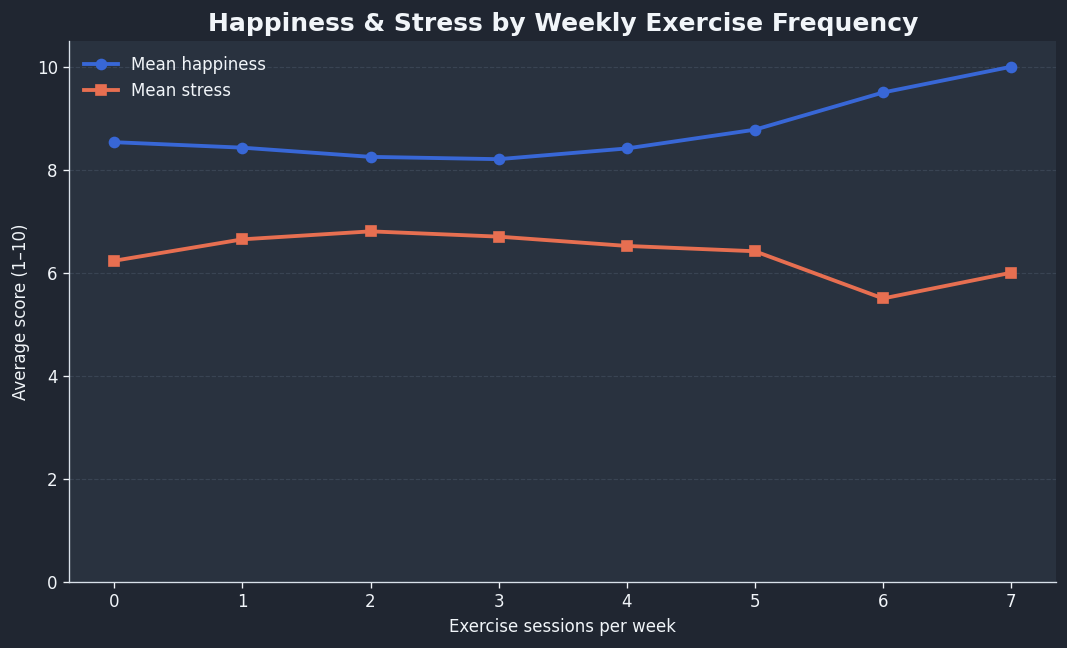

                        Users  Mean_Happiness  Mean_Stress  Mean_Sleep
Exercise_Days_Per_Week                                                
0.00                       43            8.53         6.23        6.33
1.00                       91            8.43         6.65        6.44
2.00                      132            8.25         6.80        6.20
3.00                      117            8.21         6.70        6.19
4.00                       75            8.41         6.52        6.24
5.00                       36            8.78         6.42        6.67
6.00                        4            9.50         5.50        7.00
7.00                        2           10.00         6.00        8.00


In [19]:
set_theme("slate")

exercise_summary = data.groupby("Exercise_Days_Per_Week").agg(
    Users=("Happiness", "size"),
    Mean_Happiness=("Happiness", "mean"),
    Mean_Stress=("Stress_Level", "mean"),
    Mean_Sleep=("Sleep_Quality", "mean")
).sort_index()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(exercise_summary.index, exercise_summary["Mean_Happiness"],
         marker="o", linewidth=2.3, color=COLORS["blue"], label="Mean happiness")
ax.plot(exercise_summary.index, exercise_summary["Mean_Stress"],
         marker="s", linewidth=2.3, color=COLORS["coral"], label="Mean stress")
ax.set_title("Happiness & Stress by Weekly Exercise Frequency")
ax.set_xlabel("Exercise sessions per week")
ax.set_ylabel("Average score (1–10)")
ax.set_ylim(0, 10.5)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(exercise_summary.round(2).to_string())

## 12 · Platform Comparisons

Platform averages should be interpreted with sample sizes in mind. Differences are descriptive and not proof that a platform causes a specific outcome.

In [20]:
platform_summary = data.groupby("Social_Media_Platform").agg(
    Users=("User_ID", "count"),
    Avg_Screen_Time=("Screen_Time_Hours", "mean"),
    Avg_Sleep=("Sleep_Quality", "mean"),
    Avg_Stress=("Stress_Level", "mean"),
    Avg_Happiness=("Happiness", "mean")
).sort_values("Users", ascending=False)
print(platform_summary.round(2).to_string())


                       Users  Avg_Screen_Time  Avg_Sleep  Avg_Stress  Avg_Happiness
Social_Media_Platform                                                              
TikTok                    95             5.46       6.46        6.59           8.38
X (Twitter)               88             5.31       6.39        6.45           8.65
LinkedIn                  87             5.29       6.55        6.46           8.52
Facebook                  81             5.66       6.10        6.67           8.35
YouTube                   75             5.48       6.33        6.64           8.31
Instagram                 74             6.08       5.91        6.96           7.99


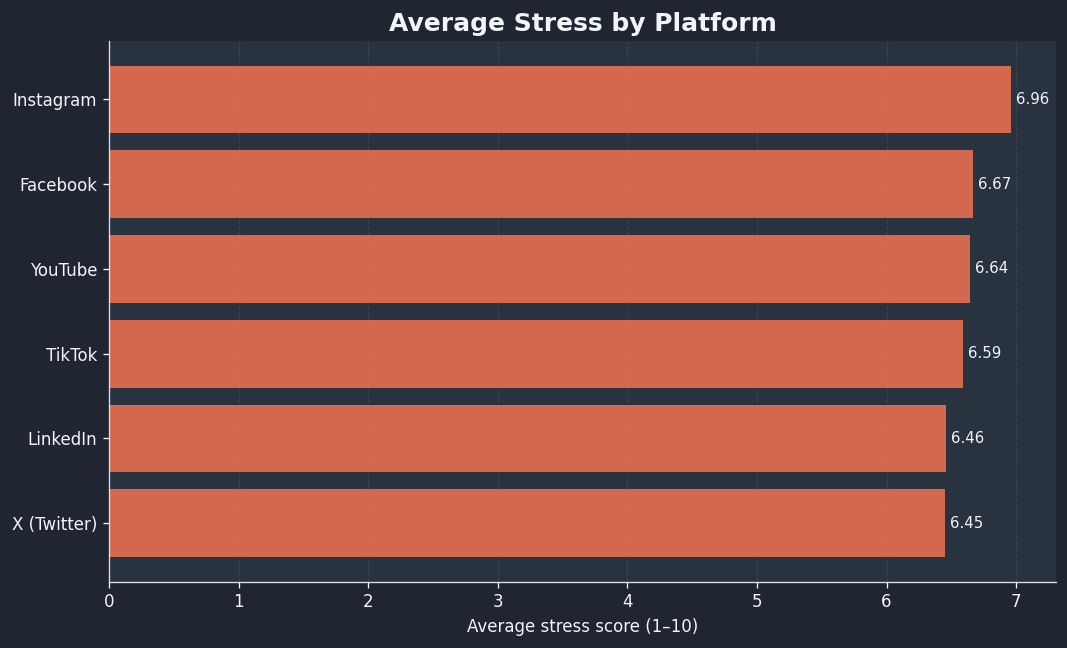

In [21]:
set_theme("slate")

fig, ax = plt.subplots(figsize=(9, 5.5))
platform_order = platform_summary.sort_values("Avg_Stress")["Avg_Stress"]
bars = ax.barh(platform_order.index, platform_order.values,
                color=COLORS["coral"], alpha=0.9)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_title("Average Stress by Platform")
ax.set_xlabel("Average stress score (1–10)")
style_ax(ax, "x")
plt.tight_layout()
plt.show()

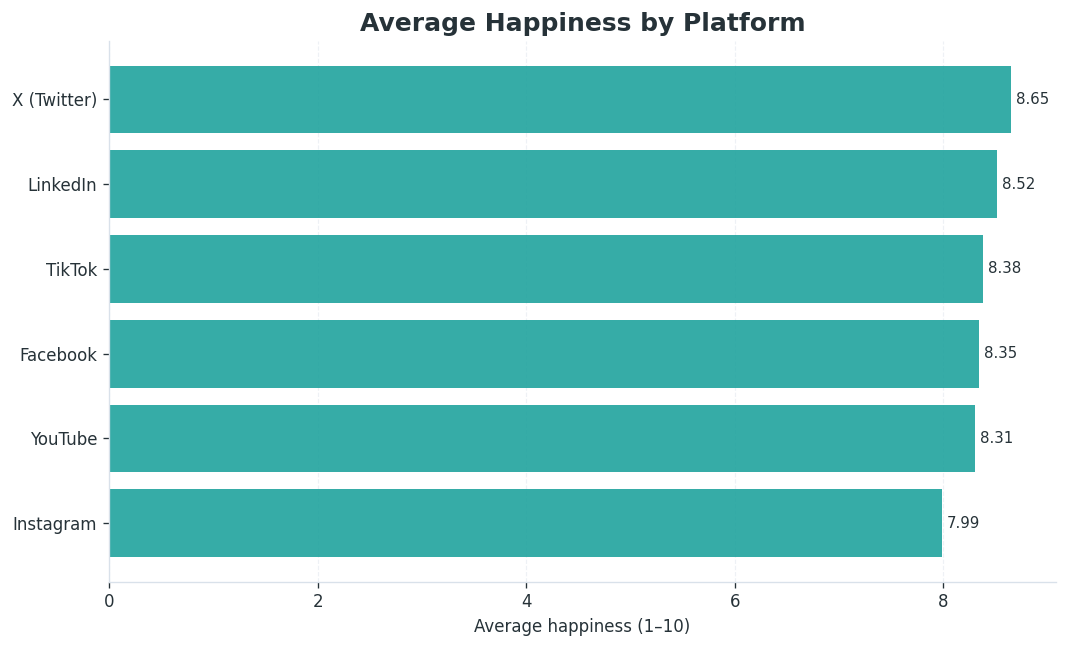

In [22]:
set_theme("clean")

fig, ax = plt.subplots(figsize=(9, 5.5))
happiness_platform = platform_summary.sort_values("Avg_Happiness")["Avg_Happiness"]
bars = ax.barh(happiness_platform.index, happiness_platform.values,
                color=COLORS["teal"], alpha=0.9)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_title("Average Happiness by Platform")
ax.set_xlabel("Average happiness (1–10)")
style_ax(ax, "x")
plt.tight_layout()
plt.show()

## 13 · Demographic Comparisons

### Average scores by gender

In [23]:
gender_summary = data.groupby("Gender").agg(
    Users=("User_ID", "count"),
    Avg_Screen_Time=("Screen_Time_Hours", "mean"),
    Avg_Sleep=("Sleep_Quality", "mean"),
    Avg_Stress=("Stress_Level", "mean"),
    Avg_Happiness=("Happiness", "mean")
)
print(gender_summary.round(2).to_string())


        Users  Avg_Screen_Time  Avg_Sleep  Avg_Stress  Avg_Happiness
Gender                                                              
Female    229             5.51       6.28        6.60           8.37
Male      248             5.59       6.29        6.63           8.35
Other      23             5.07       6.65        6.61           8.78


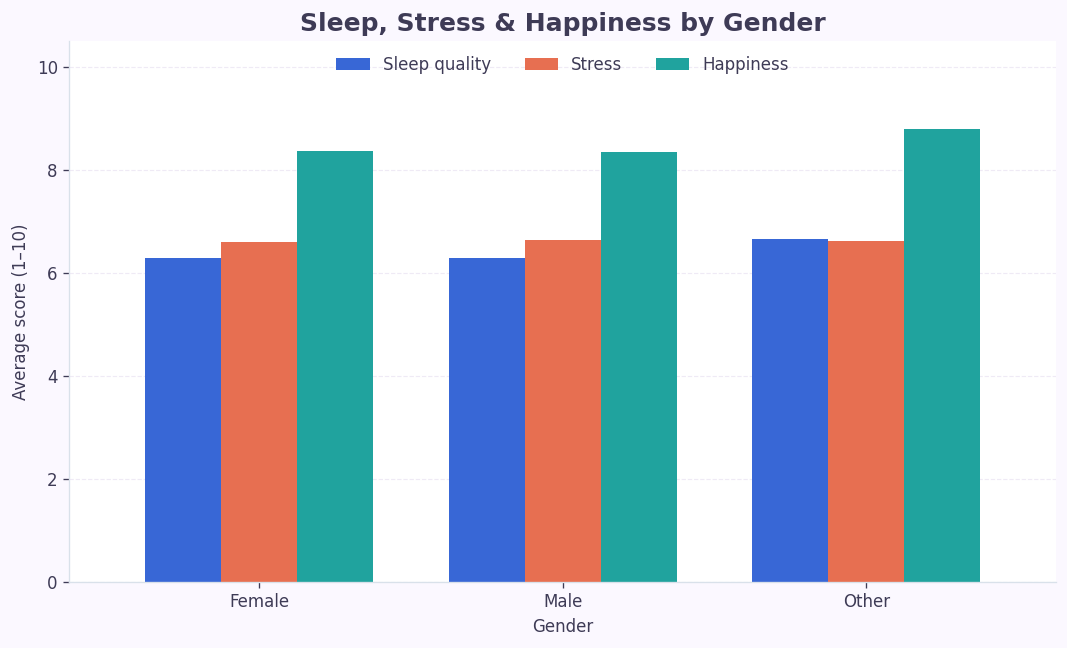

In [24]:
set_theme("pastel")

metrics = ["Avg_Sleep", "Avg_Stress", "Avg_Happiness"]
metric_labels = ["Sleep quality", "Stress", "Happiness"]
gender_metrics = gender_summary[metrics]

fig, ax = plt.subplots(figsize=(9, 5.5))
gender_metrics.plot(kind="bar", ax=ax, color=[COLORS["blue"], COLORS["coral"], COLORS["teal"]], width=0.75)
ax.set_title("Sleep, Stress & Happiness by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Average score (1–10)")
ax.set_ylim(0, 10.5)
ax.legend(metric_labels, frameon=False, ncol=3, loc="upper center")
ax.tick_params(axis="x", rotation=0)
style_ax(ax)
plt.tight_layout()
plt.show()

### Screen time by gender

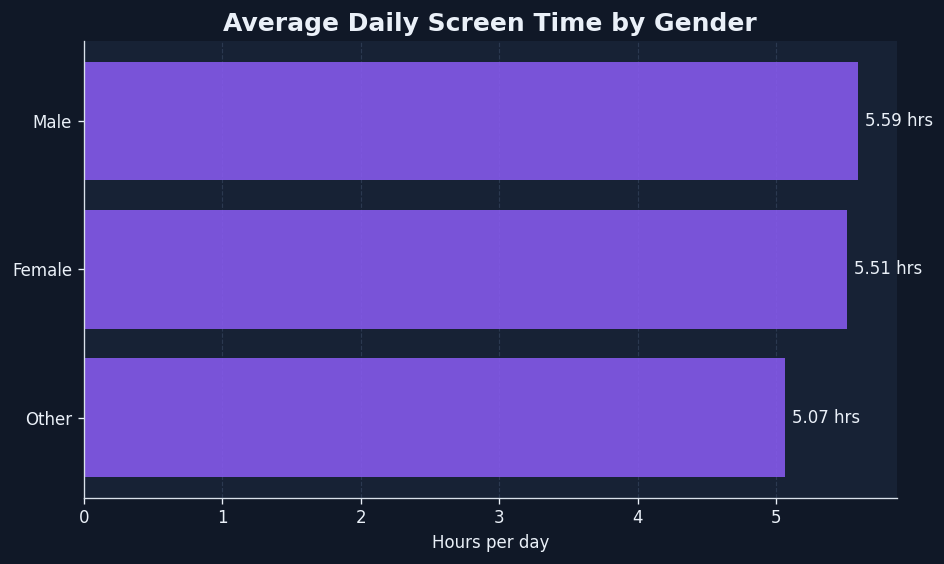

In [25]:
set_theme("dark")

screen_gender = data.groupby("Gender")["Screen_Time_Hours"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(screen_gender.index, screen_gender.values,
                color=COLORS["purple"], alpha=0.85)
ax.bar_label(bars, fmt="%.2f hrs", padding=4)
ax.set_title("Average Daily Screen Time by Gender")
ax.set_xlabel("Hours per day")
style_ax(ax, "x")
plt.tight_layout()
plt.show()

## 14 · Correlation Overview

Correlation helps summarize linear relationships between numeric variables. It does not imply causation.

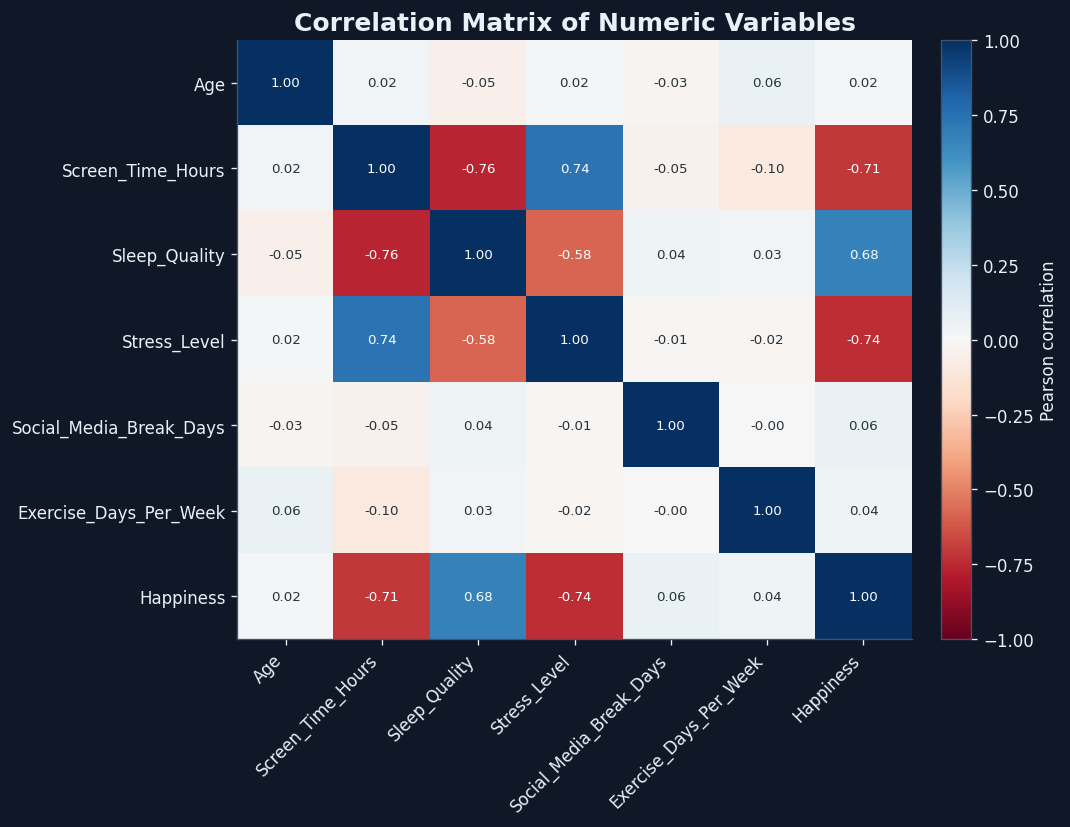

                          Age  Screen_Time_Hours  Sleep_Quality  Stress_Level  Social_Media_Break_Days  Exercise_Days_Per_Week  Happiness
Age                      1.00               0.02          -0.05          0.02                    -0.03                    0.06       0.02
Screen_Time_Hours        0.02               1.00          -0.76          0.74                    -0.05                   -0.10      -0.71
Sleep_Quality           -0.05              -0.76           1.00         -0.58                     0.04                    0.03       0.68
Stress_Level             0.02               0.74          -0.58          1.00                    -0.01                   -0.02      -0.74
Social_Media_Break_Days -0.03              -0.05           0.04         -0.01                     1.00                   -0.00       0.06
Exercise_Days_Per_Week   0.06              -0.10           0.03         -0.02                    -0.00                    1.00       0.04
Happiness                0.02     

In [26]:
set_theme("dark")

numeric_for_corr = [
    "Age", "Screen_Time_Hours", "Sleep_Quality", "Stress_Level",
    "Social_Media_Break_Days", "Exercise_Days_Per_Week", "Happiness"
]
corr_matrix = data[numeric_for_corr].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8,
                color="white" if abs(corr_matrix.iloc[i, j]) > 0.55 else COLORS["dark"])
ax.set_title("Correlation Matrix of Numeric Variables")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
plt.tight_layout()
plt.show()

print(corr_matrix.round(2).to_string())

## 15 · Outlier Investigation (IQR)

Outlier flags are used for investigation, not automatic deletion. A statistically unusual value may still be valid.

In [27]:
outlier_column = "Screen_Time_Hours"
q1 = data[outlier_column].quantile(0.25)
q3 = data[outlier_column].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (data[outlier_column] < lower_bound) | (data[outlier_column] > upper_bound)
outlier_rows = data.loc[outlier_mask]

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Flagged records: {outlier_mask.sum()}")

print(outlier_rows.to_string())

Q1: 4.30
Q3: 6.70
IQR: 2.40
Lower bound: 0.70
Upper bound: 10.30
Flagged records: 2
    User_ID  Age  Gender  Screen_Time_Hours  Sleep_Quality  Stress_Level  Social_Media_Break_Days  Exercise_Days_Per_Week Social_Media_Platform  Happiness Age_Group Screen_Time_Band
248    U249   46  Female              10.80           5.00         10.00                     2.00                    3.00             Instagram       4.00     45–49               >8
325    U326   27    Male              10.80           2.00          9.00                     3.00                    2.00           X (Twitter)       5.00     25–29               >8


                        Flagged  Non-flagged
Screen_Time_Hours         10.80         5.51
Sleep_Quality              3.50         6.32
Stress_Level               9.50         6.61
Happiness                  4.50         8.39
Exercise_Days_Per_Week     2.50         2.45


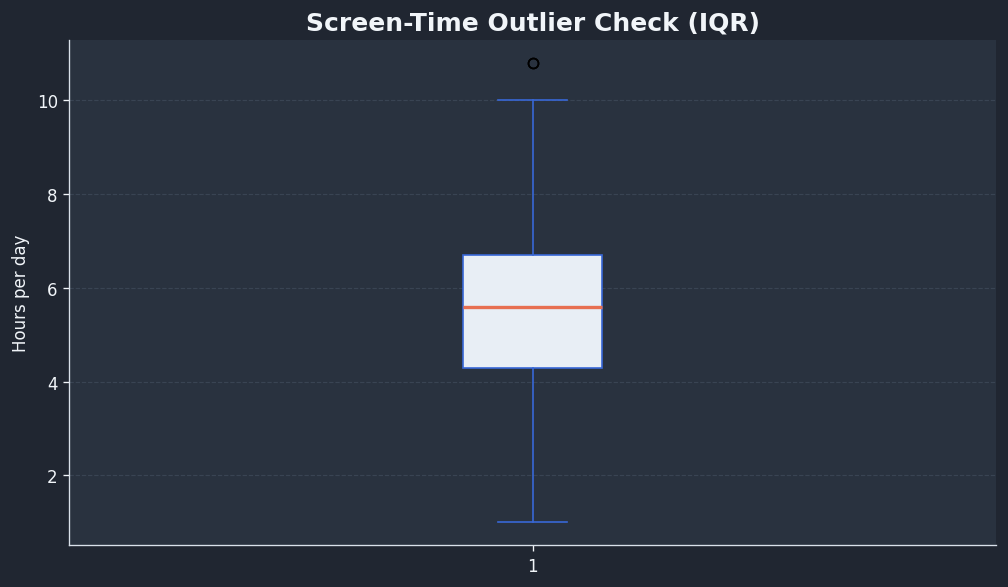

In [28]:
set_theme("slate")

comparison_columns = ["Screen_Time_Hours", "Sleep_Quality", "Stress_Level",
                     "Happiness", "Exercise_Days_Per_Week"]
outlier_compare = pd.DataFrame({
    "Flagged": data.loc[outlier_mask, comparison_columns].mean(),
    "Non-flagged": data.loc[~outlier_mask, comparison_columns].mean()
})
print(outlier_compare.round(2).to_string())

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.boxplot(data[outlier_column].dropna(), vert=True, patch_artist=True,
           boxprops={"facecolor": COLORS["light"], "color": COLORS["blue"]},
           medianprops={"color": COLORS["coral"], "linewidth": 2},
           whiskerprops={"color": COLORS["blue"]},
           capprops={"color": COLORS["blue"]})
ax.set_title("Screen-Time Outlier Check (IQR)")
ax.set_ylabel("Hours per day")
style_ax(ax)
plt.tight_layout()
plt.show()


## 16 · Automated Insight Summary

These summaries are generated from the current data. Treat them as starting points for interpretation, not final causal conclusions.

In [29]:
# Correlation-based summaries
correlations = data[numeric_for_corr].corr()

def corr_value(a, b):
    return correlations.loc[a, b]

print("CORRELATION SNAPSHOT")
print(f"Screen time ↔ Happiness: {corr_value('Screen_Time_Hours', 'Happiness'):.2f}")
print(f"Screen time ↔ Stress: {corr_value('Screen_Time_Hours', 'Stress_Level'):.2f}")
print(f"Sleep ↔ Happiness: {corr_value('Sleep_Quality', 'Happiness'):.2f}")
print(f"Sleep ↔ Stress: {corr_value('Sleep_Quality', 'Stress_Level'):.2f}")
print(f"Break days ↔ Happiness: {corr_value('Social_Media_Break_Days', 'Happiness'):.2f}")
print(f"Exercise ↔ Happiness: {corr_value('Exercise_Days_Per_Week', 'Happiness'):.2f}")

# Platform group with highest/lowest means (among represented platforms)
best_platform_happiness = platform_summary["Avg_Happiness"].idxmax()
lowest_platform_happiness = platform_summary["Avg_Happiness"].idxmin()
highest_platform_stress = platform_summary["Avg_Stress"].idxmax()
lowest_platform_stress = platform_summary["Avg_Stress"].idxmin()

print("\\nGROUP COMPARISONS")
print(f"Highest mean happiness platform: {best_platform_happiness}")
print(f"Lowest mean happiness platform: {lowest_platform_happiness}")
print(f"Highest mean stress platform: {highest_platform_stress}")
print(f"Lowest mean stress platform: {lowest_platform_stress}")

print("\\nSAMPLE SIZE REMINDER")
print("Always report group sizes and avoid over-interpreting very small groups.")

CORRELATION SNAPSHOT
Screen time ↔ Happiness: -0.71
Screen time ↔ Stress: 0.74
Sleep ↔ Happiness: 0.68
Sleep ↔ Stress: -0.58
Break days ↔ Happiness: 0.06
Exercise ↔ Happiness: 0.04
\nGROUP COMPARISONS
Highest mean happiness platform: X (Twitter)
Lowest mean happiness platform: Instagram
Highest mean stress platform: Instagram
Lowest mean stress platform: X (Twitter)
\nSAMPLE SIZE REMINDER
Always report group sizes and avoid over-interpreting very small groups.


## 17 · Key Findings & Practical Recommendations

Use the generated statistics and plots above to support these themes:

1. **Screen time and well-being:** Describe the observed relationship between daily screen time, happiness, and stress. Avoid suggesting screen time alone determines well-being.
2. **Sleep quality:** Evaluate whether sleep scores align with stress and happiness in this sample.
3. **Breaks and exercise:** Check whether their relationships are consistent or weak. Avoid treating group averages as proof of effects.
4. **Group comparisons:** Demographic or platform differences may be small and influenced by sample sizes or other variables.

### Practical recommendations
- Encourage balanced, intentional screen use rather than a one-size-fits-all rule.
- Treat sleep as a relevant lifestyle factor worth tracking alongside digital habits.
- Evaluate personal patterns instead of making assumptions based on gender or platform.
- Use larger, more representative samples and repeated measurements for stronger conclusions.

## 18 · Limitations

- The dataset contains a limited sample; representativeness is not established.
- Several measures are self-reported and may be affected by recall or response bias.
- Observational data cannot establish causality.
- Small subgroup counts can make group averages unstable.
- Other factors—daily routines, academic/work pressure, health, and personal circumstances—may influence the reported measures.
- Statistical outliers are not automatically data errors.

---

## 19 · Executive Summary

### Research question
How are screen time, sleep, social-media breaks, and exercise associated with reported stress and happiness?

### Main takeaway
Interpret the evidence as patterns of association in this sample. Screen time and sleep may show clearer relationships with well-being than some other lifestyle measures, but the strength and consistency of each pattern should be verified from the dataset's calculated results.

### Final note
**Association is not causation.** The findings describe this dataset and should not be generalized to everyone without additional evidence.

---
### Project completed
*Mental Health & Social Media Balance — Exploratory Data Analysis*

**Tools:** Python · Pandas · NumPy · Matplotlib